### 1. Generate Synthetic Loan Dataset
We will create a synthetic dataset representing loan applicants, including features like Credit Score, Income, and Loan Amount, with a target variable `Loan_Approved` (0 for rejection, 1 for approval).

In [3]:
import numpy as np
import pandas as pd

# Seed for reproducibility
np.random.seed(42)

# Generate synthetic data (7 columns total: 6 features + 1 target)
n_samples = 1000
credit_score = np.random.randint(300, 850, size=n_samples)
income = np.random.randint(20000, 150000, size=n_samples)
loan_amount = np.random.randint(5000, 100000, size=n_samples)
age = np.random.randint(18, 70, size=n_samples)
employment_length = np.random.randint(0, 40, size=n_samples)
debt_to_income = np.round(np.random.uniform(0.1, 0.6, size=n_samples), 2)

# Logistically simulate loan approval based on the new features
# Higher credit score, income, and employment length increase approval chances
# Higher loan amount and debt-to-income ratio decrease approval chances
logits = (
    0.015 * (credit_score - 600) +
    0.00005 * (income - 50000) -
    0.00003 * (loan_amount - 30000) +
    0.05 * (employment_length - 5) -
    3.0 * (debt_to_income - 0.3)
)
prob = 1 / (1 + np.exp(-logits))
loan_approved = np.where(prob > np.random.rand(n_samples), 1, 0)

# Create DataFrame
df = pd.DataFrame({
    'Credit_Score': credit_score,
    'Income': income,
    'Loan_Amount': loan_amount,
    'Age': age,
    'Employment_Length': employment_length,
    'Debt_to_Income': debt_to_income,
    'Loan_Approved': loan_approved
})

display(df.head())
print(f"Dataset Shape: {df.shape}")
print(df['Loan_Approved'].value_counts(normalize=True))

,Credit_Score,Income,Loan_Amount,Age,Employment_Length,Debt_to_Income,Loan_Approved
0,402,126296,93009,51,0,0.47,0
1,735,101182,60409,43,37,0.35,1
2,570,102565,33625,22,23,0.34,1
3,406,49402,86040,52,30,0.52,0
4,371,24263,29089,45,25,0.28,0


Dataset Shape: (1000, 7)
Loan_Approved
1    0.621
0    0.379
Name: proportion, dtype: float64


### 2. Train Logistic Regression Model
Now we will split the dataset into 80% train and 20% test, scale the features, train the Logistic Regression model, and print the evaluation metrics.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Features and target variable (using all 6 features now)
X = df[['Credit_Score', 'Income', 'Loan_Amount', 'Age', 'Employment_Length', 'Debt_to_Income']]
y = df['Loan_Approved']

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Standardize features for logistic regression optimization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression Model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

# Evaluation
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy Score: 0.81

Confusion Matrix:
 [[ 58  18]
 [ 20 104]]

Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.76      0.75        76
           1       0.85      0.84      0.85       124

    accuracy                           0.81       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.81      0.81      0.81       200



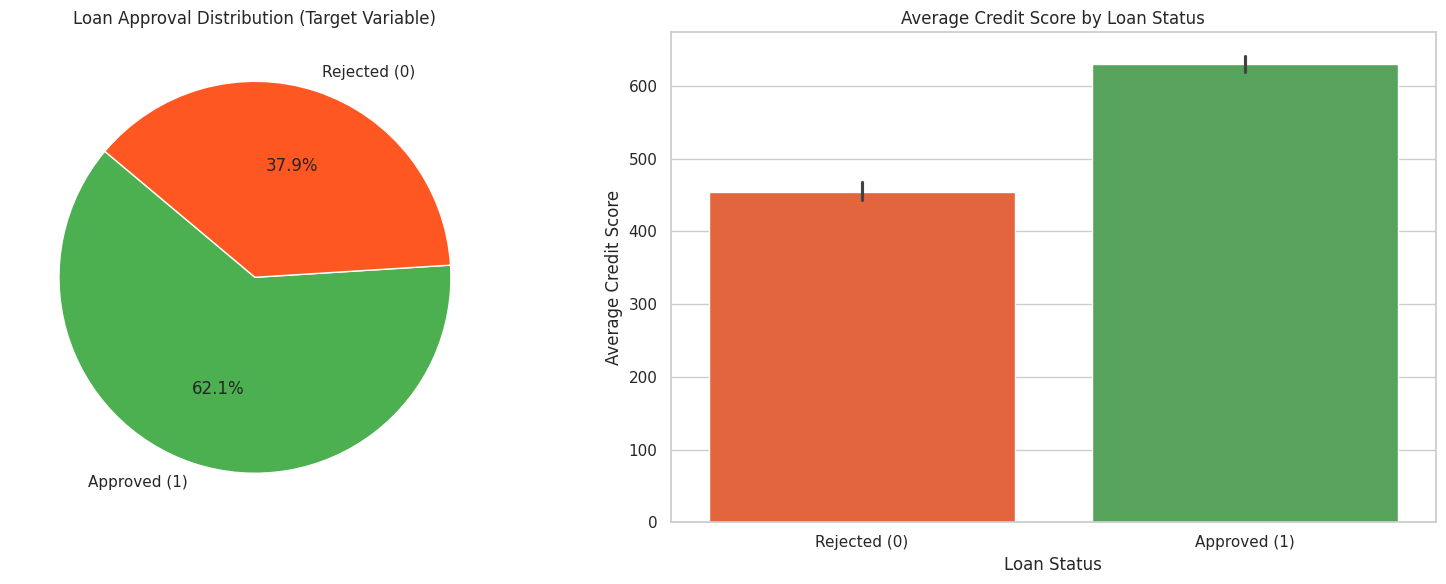

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Set up the matplotlib figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Pie Chart for Target Variable Distribution
class_counts = df['Loan_Approved'].value_counts()
labels = ['Approved (1)', 'Rejected (0)'] if class_counts.index[0] == 1 else ['Rejected (0)', 'Approved (1)']

axes[0].pie(class_counts, labels=labels, autopct='%1.1f%%', startangle=140, colors=['#4CAF50', '#FF5722'])
axes[0].set_title('Loan Approval Distribution (Target Variable)')

# 2. Bar Chart comparing Average Credit Score for Approved vs. Rejected
sns.barplot(x='Loan_Approved', y='Credit_Score', data=df, ax=axes[1], palette=['#FF5722', '#4CAF50'], hue='Loan_Approved', legend=False)
axes[1].set_title('Average Credit Score by Loan Status')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Rejected (0)', 'Approved (1)'])
axes[1].set_xlabel('Loan Status')
axes[1].set_ylabel('Average Credit Score')

plt.tight_layout()
plt.show()

### 3. Predict on Custom Data Input
We will define a helper function to easily test new, custom loan applicant profiles using our trained model.

In [10]:
# @title Custom Loan Application Test Form { run: "auto" }

# @markdown Adjust the input values below to immediately test the model on custom data:
Credit_Score = 720  # @param {type:"slider", min:300, max:850, step:10}
Income = 85000  # @param {type:"number"}
Loan_Amount = 30000  # @param {type:"number"}
Age = 35  # @param {type:"slider", min:18, max:100, step:1}
Employment_Length = 8  # @param {type:"slider", min:0, max:50, step:1}
Debt_to_Income = 0.25  # @param {type:"slider", min:0.0, max:1.0, step:0.01}

def predict_loan_status(credit_score, income, loan_amount, age, employment_length, debt_to_income):
    # 1. Structure the custom inputs into a pandas DataFrame matching the training features
    custom_input = pd.DataFrame([{
        'Credit_Score': credit_score,
        'Income': income,
        'Loan_Amount': loan_amount,
        'Age': age,
        'Employment_Length': employment_length,
        'Debt_to_Income': debt_to_income
    }])

    # 2. Scale the input data using the scaler fitted on the training set
    custom_input_scaled = scaler.transform(custom_input)

    # 3. Predict final decision class
    decision = model.predict(custom_input_scaled)[0]

    # 4. Calculate accuracy from evaluation variables
    actual_accuracy = accuracy_score(y_test, y_pred)

    # Display output
    status = "APPROVED" if decision == 1 else "REJECTED"
    print(f"--- Loan Application Result ---")
    print(f"Model Accuracy: {actual_accuracy:.2%}")
    print(f"Final Decision: {status}")
    print(f"-------------------------------")

# Run prediction on the form inputs
predict_loan_status(
    credit_score=Credit_Score,
    income=Income,
    loan_amount=Loan_Amount,
    age=Age,
    employment_length=Employment_Length,
    debt_to_income=Debt_to_Income
)

--- Loan Application Result ---
Model Accuracy: 81.00%
Final Decision: APPROVED
-------------------------------
